## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

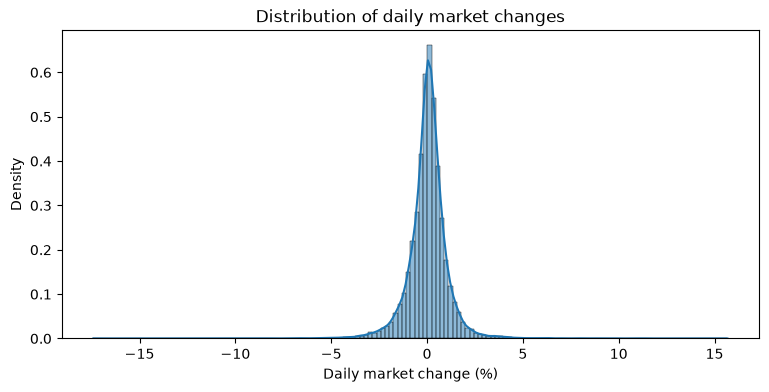

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

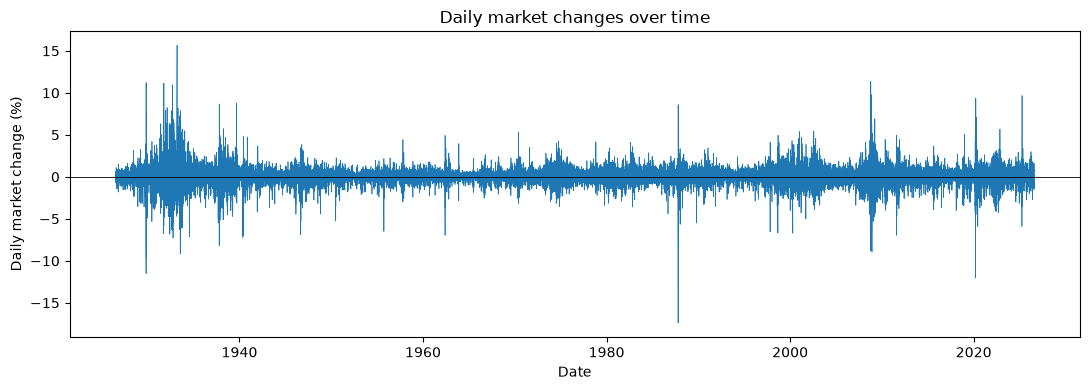

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [29]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [30]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [31]:
df[["direction_t","direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [32]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


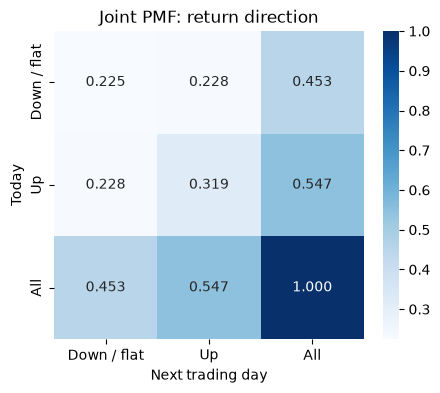

In [33]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [34]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = 'index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

Up transitions are more common as we see on the joint probability table. There are more up days in general and more than half of the time a down day today will result in an up day tomorrow. 

An up day is more likely to result in an up day tomorrow with a probability of about 0.58.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [35]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1,1, np.inf], labels = return_categories)


In [36]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [37]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [38]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

The bins have the following number of days per bin:

Small gain    9785

Small loss    7452

Near zero     3441

Large gain    2859

Large loss    2759

The most common is a small gain after a small gain, while the least likely is small gain today and then large loss tomomrrow.

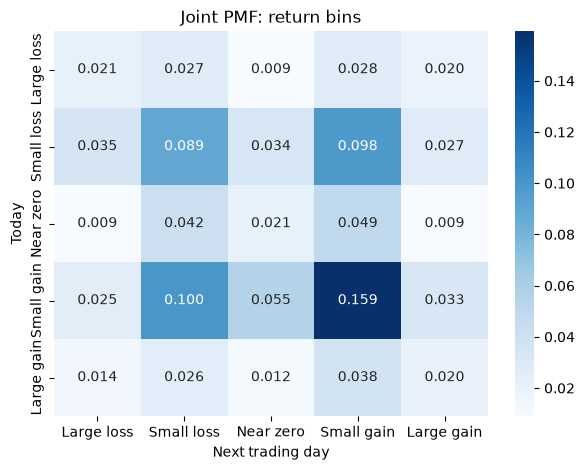

In [40]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

Small gain after small gain is the most likely transition to occur.

In [14]:
#conditional PMF 
conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditional

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

Large loss followed by large loss and large loss followed by small gain is the most common (table below shows the rest of the likely future states).

They are somewhat close to a uniform mass function but they very more in the extremes. This makes sense because on a day that has no change, the market is probably stable and will remain that way.

It is still relatively difficult to predict the next day. While we see some trends, most of the time the next day is fairly evenly spread as a result of today.

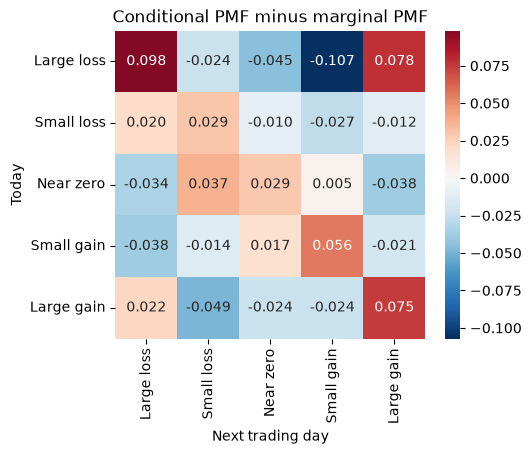

In [15]:
# Marginal PMF of tomorrow's state
next_state_pmf = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True
).sum(axis=0)

# Subtract from each row of the conditional PMF and plot
fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(
    conditional.sub(next_state_pmf, axis='columns'),
    annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax
)

ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional PMF minus marginal PMF'
)

plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

Large loss to large loss and large loss to large gain are the most likely than independence predicts. Large gain to small loss and large loss to small gain are the least independent.

Yes, if tomorrow were independent of today then every cell in this heatmap would be near 0, but that is not the case. We see trends in both direction and variablility in the heat map. 

Comparing each row to 0.2 asks if each option is equally likely while this heatmap asks if tomorrow's weather is effected by todays.

In [16]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')['market_return_pct_tp1'].describe()

/var/folders/vz/h8mfntpd1wb7y4q95y8k3lbm0000gn/T/ipykernel_93357/2658844929.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')['market_return_pct_tp1'].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


Large loss today = -0.038% tomorrow

Small loss today = -0.044% tomorrow

Near zero today = 0.015% tomorrow

Small gain today = 0.107% tomorrow

Large gain today = 0.163% tomorrow
For the min and max values, the range is much wider after the extreme days. After a large loss day, the next day ranges from about -17.41% to 11.22%, but the middle days have narrower ranges as the days get closer to a net zero result in the market.

Large gain and large loss have the largest standard deviations (1.28 and 1.72).

There is a U shaped volatility pattern with the extremes having higher volatility and the days closer to zero being more stable.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [44]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [45]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

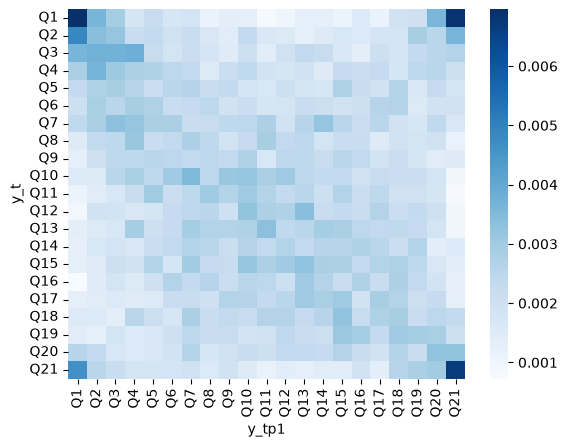

In [46]:
sns.heatmap(quantile_joint, cmap='Blues')

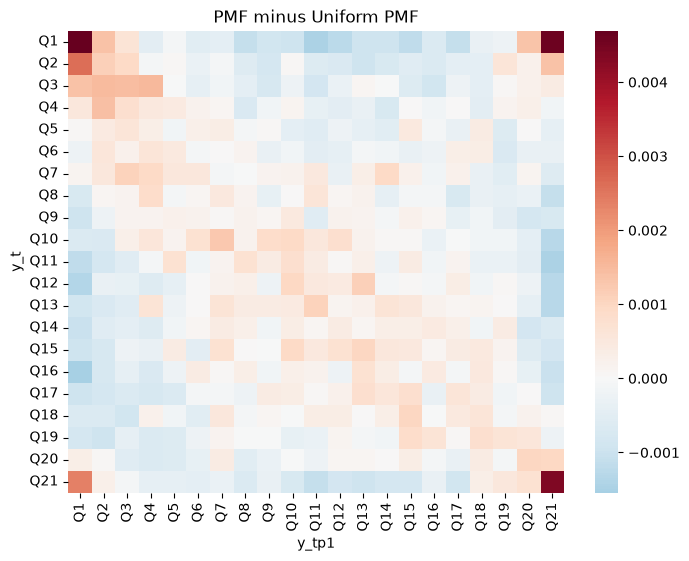

In [50]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
uniform_pmf = 1 / 21**2

pmf_diff = quantile_joint - uniform_pmf
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(pmf_diff, center=0, cmap="RdBu_r", ax=ax)
ax.set_title("PMF minus Uniform PMF")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

There is a strong diagonal correlation which means that the trend moves slowly in either direction. If one point is Q11, the likely next pint is within 2 of that point. 

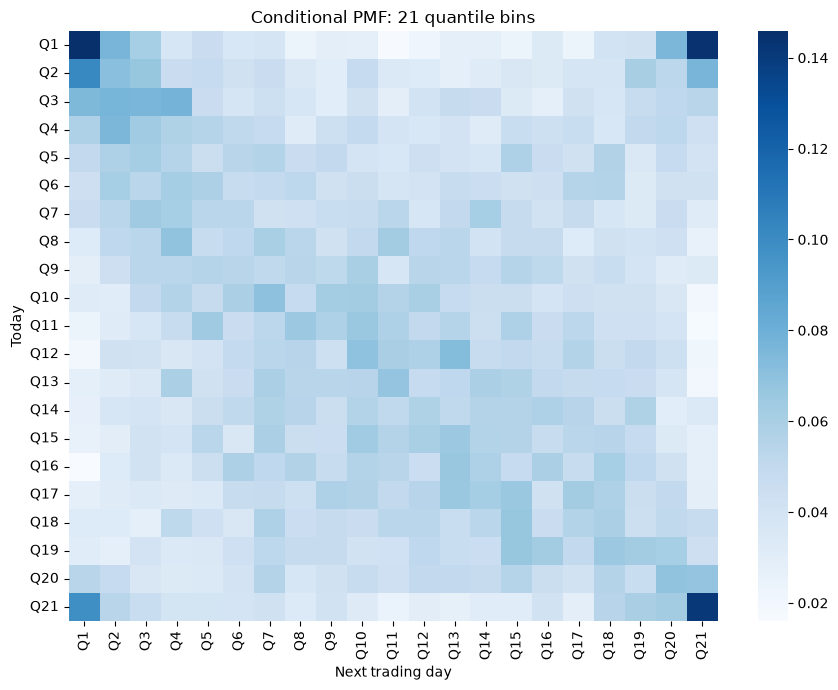

In [51]:
# compute and plot the conditional
quantile_conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(quantile_conditional, cmap='Blues', ax=ax)
ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional PMF: 21 quantile bins'
)

plt.tight_layout()
plt.show()

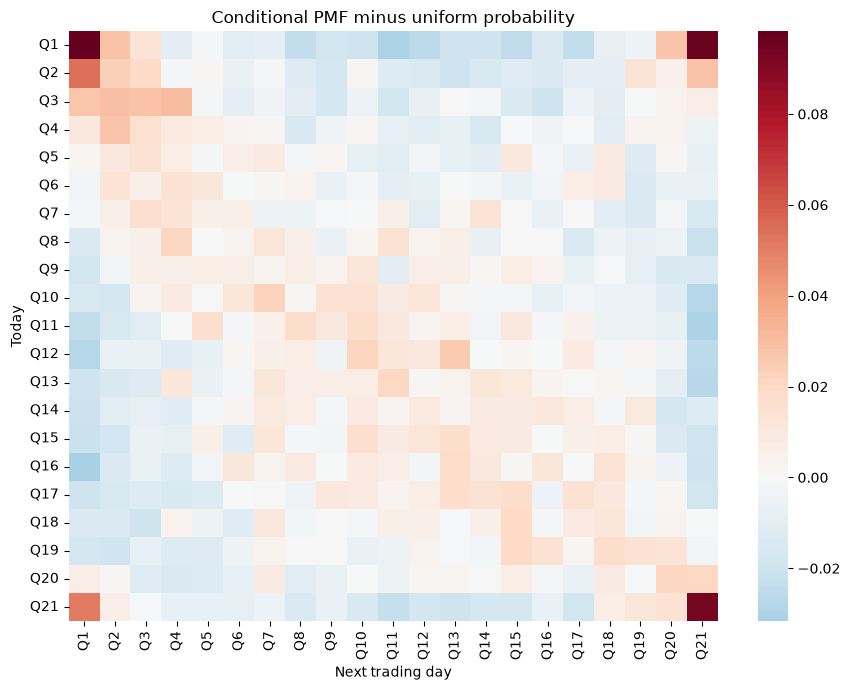

In [52]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    quantile_conditional - 1/bins,
    cmap='RdBu_r', center=0, ax=ax
)
ax.set(
    xlabel='Next trading day',
    ylabel='Today',
    title='Conditional PMF minus uniform probability'
)
plt.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

Large changes follow large changes and small changes follow small changes. When the market is volitle, it is likely jumping up and down, but when it is calm, we predict no huge changes.

In [53]:
# compute the next day's min, mean, and max conditional on each bin
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

conditional_stats = (df.groupby('y_t', observed=True)['market_return_pct_tp1'].agg(['min', 'mean', 'max']))
conditional_stats

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


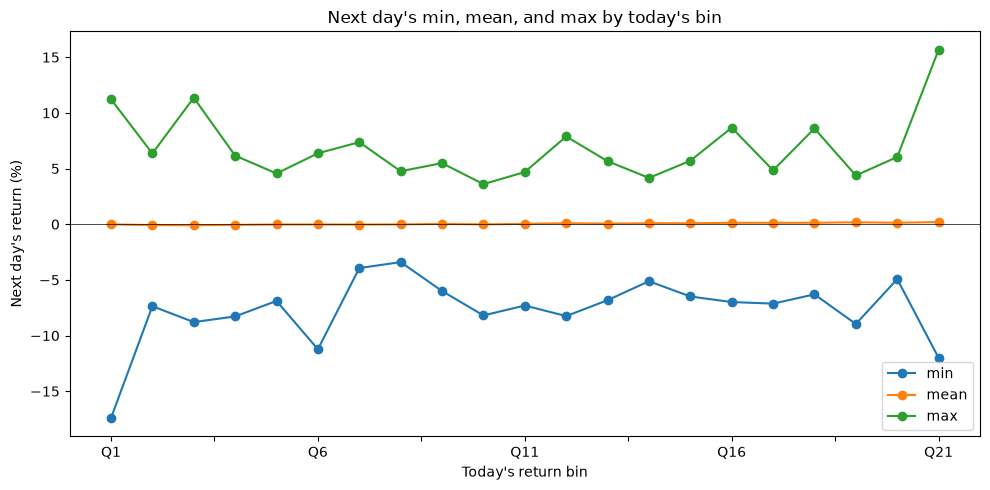

In [54]:
#plot as lines on a graph against the bins
conditional_stats.plot(figsize=(10, 5), marker='o')
plt.xlabel("Today's return bin")
plt.ylabel("Next day's return (%)")
plt.title("Next day's min, mean, and max by today's bin")
plt.axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

After a big return today, tomorrow's range is larger. When the market is volitle, it can be unpredictable.

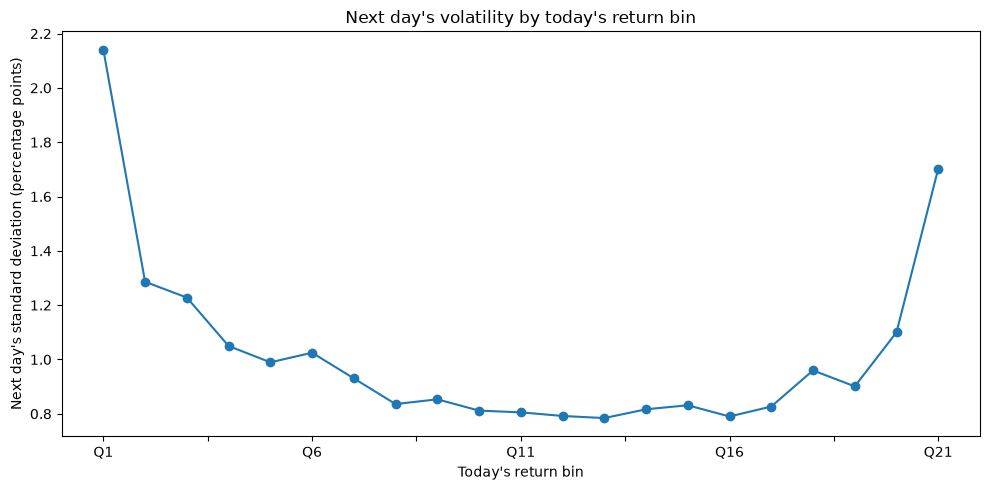

In [55]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
conditional_std = (df.groupby('y_t', observed=True)['market_return_pct_tp1'].std())

conditional_std.plot(figsize=(10, 5), marker='o')
plt.xlabel("Today's return bin")
plt.ylabel("Next day's standard deviation (percentage points)")
plt.title("Next day's volatility by today's return bin")
plt.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

There is a U shaped pattern where the more extreme return is (positive or negative) the higher the standard deviation of tomorrows result is likley to be. When the market is calm, it is more predictable. 

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

The market is always challenging to predict, and during more volitle periods it gets even more challenging. During times of a stable market, the return is more predictable but whether it is positive or negative is still hard to predict. The only trend that is clear is a stable day today will likely result in a stable day tomorrow and a day with a large change will likely follow in a day with a large change, positive or negative.